# Flight Delay Prediction (CIS 412, Fall 2025)

**Business question:** Can we flag flights likely to arrive late, so an airline or airport team can plan staff, gates and passenger communication ahead of time?

**Data:** 2,201 flights from the Washington DC area (DCA, IAD, BWI) to New York (LGA, EWR, JFK), January 2004. A flight is *delayed* if it arrived more than 15 minutes late. Source: *Data Mining for Business Analytics* (Shmueli, Bruce & Patel), derived from U.S. Bureau of Transportation Statistics data.

**Approach:** exploratory analysis, one-hot encoding of carrier / origin / destination, then a Decision Tree vs. Logistic Regression on an 80/20 split, evaluated with a confusion matrix, precision, recall and F1.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, recall_score

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
df = pd.read_csv("../data/FlightDelays.csv")
print(df.shape)
df.head()

(2201, 13)


,CRS_DEP_TIME,CARRIER,DEP_TIME,DEST,DISTANCE,FL_DATE,FL_NUM,ORIGIN,Weather,DAY_WEEK,DAY_OF_MONTH,TAIL_NUM,Flight Status
0,1455,OH,1455,JFK,184,01/01/2004,5935,BWI,0,4,1,N940CA,ontime
1,1640,DH,1640,JFK,213,01/01/2004,6155,DCA,0,4,1,N405FJ,ontime
2,1245,DH,1245,LGA,229,01/01/2004,7208,IAD,0,4,1,N695BR,ontime
3,1715,DH,1709,LGA,229,01/01/2004,7215,IAD,0,4,1,N662BR,ontime
4,1039,DH,1035,LGA,229,01/01/2004,7792,IAD,0,4,1,N698BR,ontime


## 1. Exploratory analysis

In [2]:
status = df["Flight Status"].value_counts()
print(status)
print(f"Delay rate: {status['delayed'] / len(df):.1%}")

Flight Status
ontime     1773
delayed     428
Name: count, dtype: int64
Delay rate: 19.4%


About **19% of flights are delayed**, so the classes are imbalanced. A model that always says *on time* would already be ~81% accurate, which is why recall on delayed flights matters more than raw accuracy.

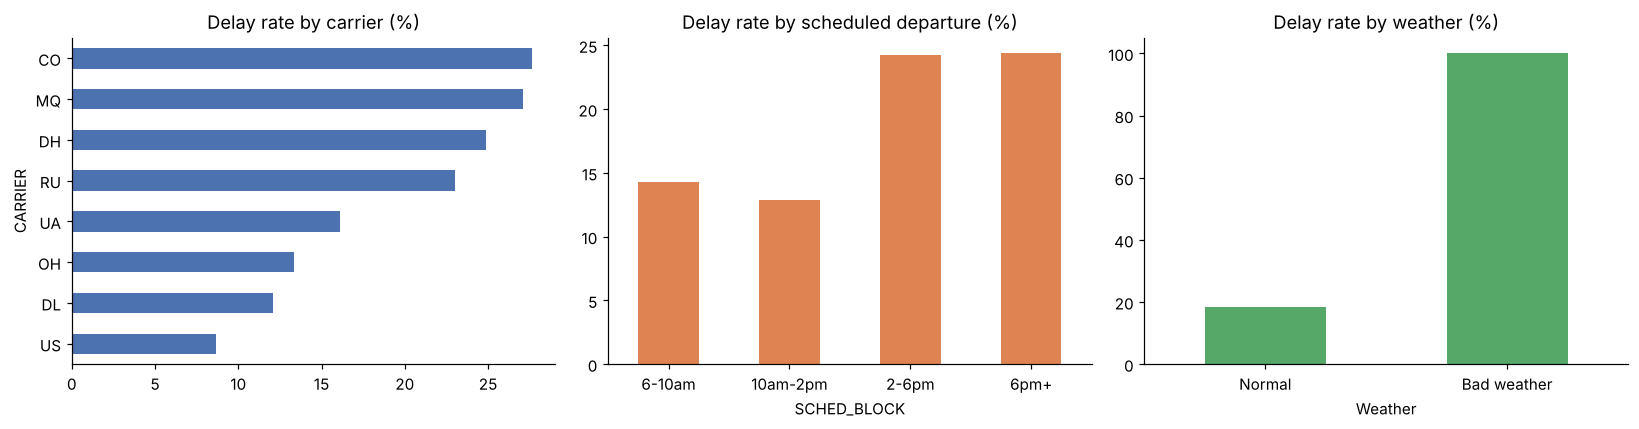

In [3]:
df["target"] = (df["Flight Status"] == "delayed").astype(int)

def time_block(t):
    if t < 1000: return "6-10am"
    if t < 1400: return "10am-2pm"
    if t < 1800: return "2-6pm"
    return "6pm+"

df["SCHED_BLOCK"] = df["CRS_DEP_TIME"].apply(time_block)
order = ["6-10am", "10am-2pm", "2-6pm", "6pm+"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
(df.groupby("CARRIER")["target"].mean().sort_values() * 100).plot(kind="barh", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by carrier (%)")
(df.groupby("SCHED_BLOCK")["target"].mean().reindex(order) * 100).plot(kind="bar", ax=axes[1], color="#DD8452")
axes[1].set_title("Delay rate by scheduled departure (%)"); axes[1].tick_params(axis="x", rotation=0)
(df.groupby("Weather")["target"].mean() * 100).rename({0: "Normal", 1: "Bad weather"}).plot(kind="bar", ax=axes[2], color="#55A868")
axes[2].set_title("Delay rate by weather (%)"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../images/eda_delay_rates.png", bbox_inches="tight")
plt.show()

In [4]:
print(df.groupby("Weather")["target"].agg(["mean", "size"]).round(3))
print()
print((df.groupby("SCHED_BLOCK")["target"].mean().reindex(order) * 100).round(1))

          mean  size
Weather             
0        0.183  2169
1        1.000    32

SCHED_BLOCK
6-10am      14.3
10am-2pm    12.8
2-6pm       24.2
6pm+        24.4
Name: target, dtype: float64


**What stands out**
- Every flight flagged with bad weather was delayed, but only ~1.5% of flights had a weather flag.
- Delays climb through the day: flights scheduled after 2pm are delayed about **24-26%** of the time vs. about **14%** before 2pm, as small delays stack up.
- Delay rates vary noticeably by carrier, so carrier is a useful predictor.

## 2. Model (course version)
Drop identifiers that don't generalise (flight number, tail number, date), one-hot encode the categorical columns, and split 80/20.

In [5]:
df_model = df.drop(columns=["FL_NUM", "TAIL_NUM", "FL_DATE", "Flight Status", "SCHED_BLOCK"])
df_encoded = pd.get_dummies(df_model, drop_first=True)
X = df_encoded.drop(columns="target")
y = df_encoded["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape

((1760, 17), (441, 17))

In [6]:
dt = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)
lr = LogisticRegression(max_iter=5000).fit(X_train, y_train)

results = {}
for name, model in [("Decision Tree", dt), ("Logistic Regression", lr)]:
    pred = model.predict(X_test)
    results[name] = accuracy_score(y_test, pred)
    print(f"=== {name} ===  accuracy {results[name]:.3f}")
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, target_names=["on time", "delayed"]))

=== Decision Tree ===  accuracy 0.848
[[354   3]
 [ 64  20]]
              precision    recall  f1-score   support

     on time       0.85      0.99      0.91       357
     delayed       0.87      0.24      0.37        84

    accuracy                           0.85       441
   macro avg       0.86      0.61      0.64       441
weighted avg       0.85      0.85      0.81       441

=== Logistic Regression ===  accuracy 0.898
[[356   1]
 [ 44  40]]
              precision    recall  f1-score   support

     on time       0.89      1.00      0.94       357
     delayed       0.98      0.48      0.64        84

    accuracy                           0.90       441
   macro avg       0.93      0.74      0.79       441
weighted avg       0.91      0.90      0.88       441



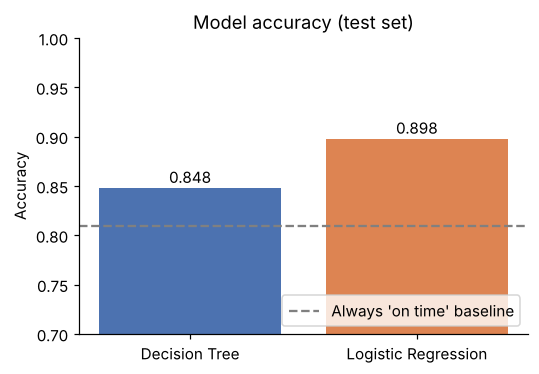

In [7]:
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(results.keys(), results.values(), color=["#4C72B0", "#DD8452"])
ax.axhline((y_test == 0).mean(), ls="--", color="gray", label="Always 'on time' baseline")
ax.set_ylim(0.7, 1.0); ax.set_ylabel("Accuracy"); ax.set_title("Model accuracy (test set)"); ax.legend(loc="lower right")
for i, v in enumerate(results.values()):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.savefig("../images/model_accuracy.png", bbox_inches="tight"); plt.show()

## 3. Leakage check (added after the course)

The course model uses `DEP_TIME`, the **actual** departure time. Combined with the scheduled time, it reveals how late the plane already left, which is most of what determines a late arrival. That information isn't available when you'd want to make the prediction (before departure), so the accuracy above is optimistic.

Below, the model is rebuilt with **only information known before departure**: scheduled time block, carrier, route, weather flag and day of week. `class_weight="balanced"` makes the model pay attention to the minority *delayed* class.

In [8]:
pre_departure = ["SCHED_BLOCK", "CARRIER", "ORIGIN", "DEST", "Weather", "DAY_WEEK"]
X2 = pd.get_dummies(df[pre_departure].astype({"DAY_WEEK": str}), drop_first=True)
X2_train, X2_test, y2_train, y2_test = train_test_split(X2, df["target"], test_size=0.2, random_state=42, stratify=df["target"])

lr2 = LogisticRegression(max_iter=5000, class_weight="balanced").fit(X2_train, y2_train)
p2 = lr2.predict(X2_test)
print(f"Accuracy:        {accuracy_score(y2_test, p2):.3f}")
print(f"Delayed recall:  {recall_score(y2_test, p2):.3f}")
print(f"ROC-AUC:         {roc_auc_score(y2_test, lr2.predict_proba(X2_test)[:, 1]):.3f}")
print(confusion_matrix(y2_test, p2))

Accuracy:        0.624
Delayed recall:  0.628
ROC-AUC:         0.705
[[221 134]
 [ 32  54]]


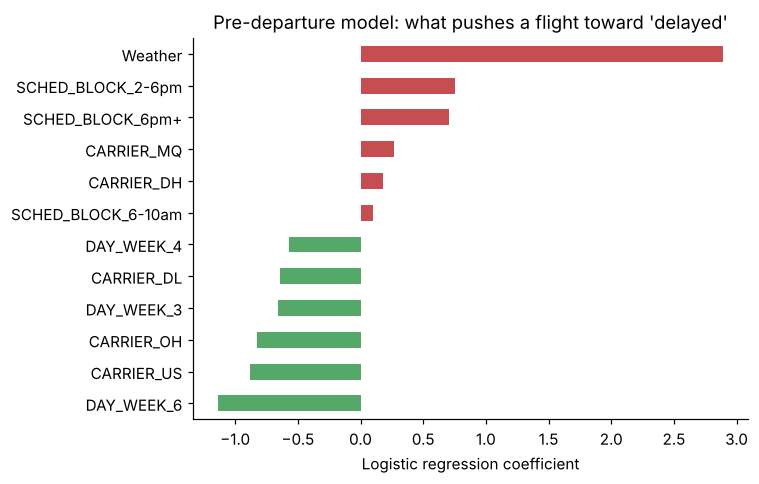

In [9]:
coefs = pd.Series(lr2.coef_[0], index=X2.columns).sort_values()
top = pd.concat([coefs.head(6), coefs.tail(6)])
fig, ax = plt.subplots(figsize=(7, 4.5))
top.plot(kind="barh", ax=ax, color=["#55A868" if v < 0 else "#C44E52" for v in top])
ax.set_title("Pre-departure model: what pushes a flight toward 'delayed'"); ax.set_xlabel("Logistic regression coefficient")
plt.tight_layout(); plt.savefig("../images/delay_drivers.png", bbox_inches="tight"); plt.show()

## 4. Takeaways

- **Course model:** Logistic Regression beat the Decision Tree on accuracy, but both mainly lean on the actual departure time.
- **Honest version:** using only pre-departure information, accuracy drops but the model still ranks risky flights better than chance and catches more of the delayed flights, which is the operationally useful part.
- **Biggest drivers:** bad weather, evening departure blocks and certain carriers/routes raise delay risk; morning departures lower it.
- **Next steps:** add more months of data (one January isn't enough to learn seasonality), tune the decision threshold to the cost of a missed delay, and try gradient-boosted trees.